# Few-Shot Learning — Matching Network (avec `easyfsl`)

Implémentation du **Matching Network** (Vinyals et al., 2016) en utilisant la librairie
[`easyfsl`](https://github.com/sicara/easy-few-shot-learning), un des 4 modèles metric-based
du projet de few-shot learning (les 3 autres — Siamese, ProtoNet, Relation Network — sont dans
des notebooks séparés, avec le même protocole d'évaluation pour pouvoir comparer les résultats
à la fin).

Différences par rapport à la version "from scratch" :
- L'attention cosinus + le mécanisme de **Full Context Embeddings** (LSTM bidirectionnel sur le
  support set + LSTM cell avec attention pour le query set) sont fournis directement par
  `easyfsl.methods.MatchingNetworks`, conformément à l'article original.
- L'encodeur (backbone) est un **ResNet18**, comme demandé par le Pr. Khalfi pour les 4 méthodes
  metric-based du projet (au lieu du ConvNet 4 blocs standard de la littérature).


## 1. Installation & imports

In [1]:
# easyfsl n'est pas installé par défaut sur Colab
!pip install easyfsl -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.8/72.8 kB 2.5 MB/s eta 0:00:00


In [2]:
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as tud
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

# Correctif de compatibilité : certaines versions récentes de PyTorch ont retiré le paramètre
# `data_source` de `Sampler.__init__`, ce qu'easyfsl (1.5.0) utilise encore en interne dans
# `TaskSampler`. Ce patch neutralise l'appel sans rien changer au comportement du sampler.
_original_sampler_init = tud.Sampler.__init__
def _patched_sampler_init(self, *args, **kwargs):
    pass
tud.Sampler.__init__ = _patched_sampler_init

from easyfsl.samplers import TaskSampler
from easyfsl.datasets import WrapFewShotDataset
from easyfsl.methods import MatchingNetworks
from easyfsl.utils import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)


Device : cuda


## 2. Chargement d'Omniglot

Omniglot est le benchmark standard des papiers de few-shot learning (Vinyals et al. l'utilisent
eux-mêmes pour Matching Networks) : 1623 caractères issus de 50 alphabets, 20 exemples par
caractère. `torchvision` fournit deux splits officiels :
- `background=True` → **964 classes** (meta-training)
- `background=False` → **659 classes** (meta-test)

On respecte ce split officiel : `train_dataset` sert à l'entraînement épisodique, `test_dataset`
(classes jamais vues à l'entraînement) sert à l'évaluation finale.

Le ResNet18 attend des images à 3 canaux : on convertit donc les images Omniglot (1 canal, noir
sur blanc) en RGB et on les redimensionne. On utilise 84x84 (taille classique en few-shot
learning, ex. mini-ImageNet) plutôt que 224x224 pour garder un entraînement épisodique rapide ;
on peut repasser à 224x224 si besoin.

`easyfsl.samplers.TaskSampler` a besoin d'un dataset qui implémente `get_labels()` (interface
`FewShotDataset`) : on utilise `easyfsl.datasets.WrapFewShotDataset`, qui enrobe n'importe quel
dataset PyTorch renvoyant `(image, label)` sans avoir à écrire de classe soi-même.

In [3]:
IMAGE_SIZE = 84

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

raw_train_dataset = datasets.Omniglot(root="./data", background=True, download=True, transform=transform)
raw_test_dataset = datasets.Omniglot(root="./data", background=False, download=True, transform=transform)

print("Train (background)  :", len(raw_train_dataset), "images")
print("Test  (evaluation)   :", len(raw_test_dataset), "images")


100%|██████████| 9.46M/9.46M [00:00<00:00, 142MB/s]
100%|██████████| 6.46M/6.46M [00:00<00:00, 75.1MB/s]


Train (background)  : 19280 images
Test  (evaluation)   : 13180 images


In [4]:
train_dataset = WrapFewShotDataset(raw_train_dataset)
test_dataset = WrapFewShotDataset(raw_test_dataset)


Scrolling dataset's labels...: 100%|██████████| 13180/13180 [00:11<00:00, 1106.37it/s]


## 3. Construction des épisodes (N-way, K-shot, Q-query)

Avec `easyfsl`, l'échantillonnage épisodique se fait via `TaskSampler`, utilisé comme
`batch_sampler` d'un `DataLoader` classique, avec `episodic_collate_fn` comme fonction de collage.
Chaque "batch" produit par le `DataLoader` correspond à un épisode complet
(support + query + labels + ids de classe).

In [5]:
def create_episodic_loader(dataset, n_way, k_shot, q_query, n_tasks, num_workers=2):
    sampler = TaskSampler(dataset, n_way=n_way, n_shot=k_shot, n_query=q_query, n_tasks=n_tasks)
    loader = DataLoader(
        dataset,
        batch_sampler=sampler,
        num_workers=num_workers,
        pin_memory=True,
        collate_fn=sampler.episodic_collate_fn,
    )
    return loader, sampler


In [6]:
# Test rapide
_, quick_sampler = create_episodic_loader(train_dataset, n_way=5, k_shot=1, q_query=5, n_tasks=1)
quick_loader = DataLoader(
    train_dataset,
    batch_sampler=quick_sampler,
    collate_fn=quick_sampler.episodic_collate_fn,
)

support_images, support_labels, query_images, query_labels, class_ids = next(iter(quick_loader))

print("Support :", support_images.shape, support_labels.shape)
print("Query   :", query_images.shape, query_labels.shape)
print("Classes de l'épisode :", class_ids)


Support : torch.Size([5, 3, 84, 84]) torch.Size([5])
Query   : torch.Size([25, 3, 84, 84]) torch.Size([25])
Classes de l'épisode : [281, 654, 114, 759, 25]


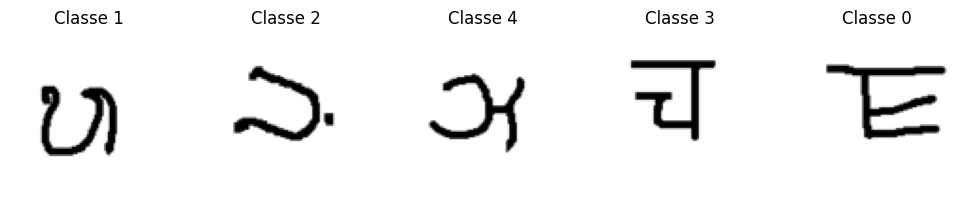

In [7]:
plt.figure(figsize=(10, 2))
for i in range(len(support_images)):
    plt.subplot(1, len(support_images), i + 1)
    # dénormalisation rapide pour l'affichage
    img = support_images[i].permute(1, 2, 0) * 0.5 + 0.5
    plt.imshow(img)
    plt.title(f"Classe {support_labels[i].item()}")
    plt.axis("off")
plt.tight_layout()
plt.show()


### Comment les 5 classes d'un épisode sont-elles choisies ? (question du prof)

C'est `TaskSampler` (dans `easyfsl.samplers.task_sampler`) qui décide, et son code source répond
directement aux questions ci-dessous :

```python
for _ in range(self.n_tasks):
    yield torch.cat([
        torch.tensor(random.sample(self.items_per_label[label], self.n_shot + self.n_query))
        for label in random.sample(sorted(self.items_per_label.keys()), self.n_way)
    ]).tolist()
```

- **Aléatoire ou pas ?** Purement aléatoire : `random.sample(..., n_way)` tire `n_way` classes
  **sans remise**, uniformément parmi *toutes* les classes disponibles du split (964 pour
  `train_dataset`, 659 pour `test_dataset`). Ce n'est pas un choix manuel, ni déterministe (sauf
  fixation de la seed) : à chaque épisode, un tirage différent.
- **Équiprobables ?** Oui. Chaque classe a exactement la même probabilité `1 / nb_classes_totales`
  d'être sélectionnée. Le tirage ne tient compte ni de la fréquence de la classe, ni d'aucune
  pondération.
- **Les labels sont-ils "proches dans les poids" ?** Non : le tirage se fait sur les **identifiants
  de classe** (des entiers), avant même que le backbone ne calcule le moindre embedding. Le
  `TaskSampler` n'a aucune connaissance des poids du réseau ni de la similarité visuelle entre
  classes — il ne fait qu'échantillonner des indices.
- **Deux classes visuellement proches peuvent-elles se retrouver dans le même épisode ?** Oui,
  rien ne l'empêche. Par analogie avec MNIST où un 3 et un 8 se ressemblent, ici deux caractères
  d'Omniglot graphiquement proches (par ex. deux traits similaires issus d'alphabets différents)
  peuvent très bien tomber dans le même épisode 5-way — c'est même statistiquement attendu de
  temps en temps puisque le tirage est uniforme et ignore la similarité visuelle. Cela rend
  certains épisodes plus difficiles que d'autres (les modèles metric-based, comme Matching
  Network, doivent alors s'appuyer sur des embeddings assez discriminants pour les séparer).
- **Et à l'intérieur d'une classe ?** Une fois les `n_way` classes tirées, `TaskSampler`
  échantillonne aussi, **uniformément et sans remise**, `n_shot + n_query` images à l'intérieur de
  chacune (`random.sample(self.items_per_label[label], ...)`) — donc le support et la query
  changent aussi à chaque épisode, même pour une classe donnée.
- **Les labels 0..N-1 utilisés dans la loss ne sont pas les vrais identifiants** : `TaskSampler`
  les réindexe localement à l'épisode (`true_class_ids`, renvoyé en 5ᵉ élément par
  `episodic_collate_fn`) — c'est pour ça qu'on peut afficher les vrais identifiants de classe
  ci-dessous pour vérifier concrètement ce qui a été tiré.


In [8]:
# Démonstration concrète : on tire 5 épisodes 5-way et on affiche les VRAIS identifiants
# de classe tirés à chaque fois (true_class_ids), pour vérifier l'aléatoire et l'équiprobabilité.
demo_sampler = TaskSampler(train_dataset, n_way=5, n_shot=1, n_query=1, n_tasks=5)
demo_loader = DataLoader(train_dataset, batch_sampler=demo_sampler, collate_fn=demo_sampler.episodic_collate_fn)

for episode_index, (_, _, _, _, true_class_ids) in enumerate(demo_loader):
    # true_class_ids sont les indices de caractères Omniglot (0 à 963 pour le split background)
    alphabets = [raw_train_dataset._characters[c].split("/")[0] for c in true_class_ids]
    print(f"Épisode {episode_index+1} — classes tirées : {true_class_ids} "
          f"(alphabets : {alphabets})")


Épisode 1 — classes tirées : [99, 389, 104, 344, 94] (alphabets : ['Alphabet_of_the_Magi', 'Armenian', 'Alphabet_of_the_Magi', 'Cyrillic', 'Anglo-Saxon_Futhorc'])
Épisode 2 — classes tirées : [643, 300, 849, 565, 633] (alphabets : ['Futurama', 'Korean', 'Asomtavruli_(Georgian)', 'Tifinagh', 'Futurama'])
Épisode 3 — classes tirées : [389, 650, 464, 854, 284] (alphabets : ['Armenian', 'Balinese', 'Arcadian', 'Asomtavruli_(Georgian)', 'Korean'])
Épisode 4 — classes tirées : [388, 167, 947, 276, 473] (alphabets : ['Armenian', 'Burmese_(Myanmar)', 'Braille', 'Korean', 'Grantha'])
Épisode 5 — classes tirées : [897, 580, 935, 216, 735] (alphabets : ['Bengali', 'Japanese_(hiragana)', 'Ojibwe_(Canadian_Aboriginal_Syllabics)', 'N_Ko', 'Sanskrit'])


## 4. Backbone : ResNet18

Suivant la convention `easyfsl`, on retire la dernière couche `fc` du ResNet18 (qui projette vers
1000 classes ImageNet) et on la remplace par un simple `Flatten`, pour que le backbone renvoie
directement le vecteur d'embedding (dimension 512, sortie du global average pooling).

In [9]:
def build_resnet18_backbone(pretrained=False):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    backbone = models.resnet18(weights=weights)
    feature_dimension = backbone.fc.in_features  # 512
    backbone.fc = nn.Flatten()
    return backbone, feature_dimension


backbone, FEATURE_DIMENSION = build_resnet18_backbone(pretrained=False)
print("Dimension des embeddings :", FEATURE_DIMENSION)


Dimension des embeddings : 512


## 5. Matching Network

`easyfsl.methods.MatchingNetworks` implémente le mécanisme complet de l'article original :

1. Extraction des embeddings du support et de la query par le backbone (ResNet18).
2. **Full Context Embeddings** : les embeddings du support sont recontextualisés par un LSTM
   bidirectionnel (`g`), ceux de la query par une LSTM cell avec attention sur le support (`f`).
3. **Attention** : similarité cosinus entre chaque query et chaque exemple de support, suivie
   d'un softmax — exactement la distance cosinus demandée par le Pr. Khalfi pour ce projet.
4. Prédiction = combinaison pondérée (par l'attention) des labels one-hot du support :

$$\hat{y} = \sum_{i=1}^{S} a(\hat{x}, x_i)\, y_i \qquad a(\hat{x}, x_i) = \frac{\exp(\cos(f(\hat{x}), g(x_i)))}{\sum_j \exp(\cos(f(\hat{x}), g(x_j)))}$$

Le modèle renvoie des **log-probabilités** : on utilise donc `nn.NLLLoss` (et non
`CrossEntropyLoss`) pour l'entraînement.

In [10]:
matching_model = MatchingNetworks(backbone, feature_dimension=FEATURE_DIMENSION).to(device)
print(matching_model)


MatchingNetworks(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True,

### 5.1 Entraînement

In [11]:
N_WAY = 5
K_SHOT = 1
Q_QUERY = 5
N_TRAINING_EPISODES = 1000

train_loader, _ = create_episodic_loader(
    train_dataset, n_way=N_WAY, k_shot=K_SHOT, q_query=Q_QUERY, n_tasks=N_TRAINING_EPISODES
)

matching_optimizer = optim.Adam(matching_model.parameters(), lr=1e-4)
criterion = nn.NLLLoss()  # Matching Networks -> sorties en log-probabilités

matching_losses, matching_accuracies = [], []


In [12]:
def fit_on_episode(model, support_images, support_labels, query_images, query_labels, optimizer, criterion):
    model.train()
    optimizer.zero_grad()

    model.process_support_set(support_images.to(device), support_labels.to(device))
    log_probabilities = model(query_images.to(device))

    query_labels = query_labels.to(device)
    loss = criterion(log_probabilities, query_labels)

    loss.backward()
    optimizer.step()

    predictions = torch.argmax(log_probabilities, dim=1)
    accuracy = (predictions == query_labels).float().mean()

    return loss.item(), accuracy.item()


for episode_index, (support_images, support_labels, query_images, query_labels, _) in enumerate(train_loader):
    loss, accuracy = fit_on_episode(
        matching_model, support_images, support_labels, query_images, query_labels,
        matching_optimizer, criterion,
    )

    matching_losses.append(loss)
    matching_accuracies.append(accuracy)

    if (episode_index + 1) % 200 == 0:
        print(f"Episode [{episode_index+1}/{N_TRAINING_EPISODES}] "
              f"Loss: {np.mean(matching_losses[-200:]):.4f}  "
              f"Acc: {np.mean(matching_accuracies[-200:])*100:.2f}%")


Episode [200/1000] Loss: 0.7483  Acc: 72.32%
Episode [400/1000] Loss: 0.3982  Acc: 85.76%
Episode [600/1000] Loss: 0.2641  Acc: 91.06%
Episode [800/1000] Loss: 0.2076  Acc: 93.42%
Episode [1000/1000] Loss: 0.1417  Acc: 95.18%


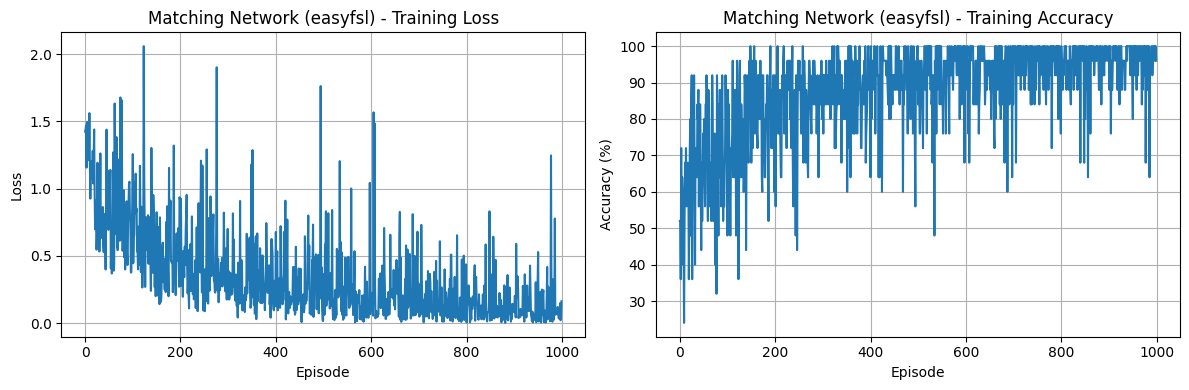

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(matching_losses)
axes[0].set_title("Matching Network (easyfsl) - Training Loss")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Loss")
axes[0].grid()

axes[1].plot([a * 100 for a in matching_accuracies])
axes[1].set_title("Matching Network (easyfsl) - Training Accuracy")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid()

plt.tight_layout()
plt.show()


### 5.2 Évaluation (5-way 1-shot / 5-way 5-shot)

In [14]:
N_EVAL_TASKS = 100
Q_QUERY_EVAL = 15

def evaluate_matching(model, dataset, n_way, k_shot, q_query=Q_QUERY_EVAL, n_tasks=N_EVAL_TASKS):
    loader, _ = create_episodic_loader(dataset, n_way=n_way, k_shot=k_shot, q_query=q_query, n_tasks=n_tasks)
    per_task_accuracies = []

    model.eval()
    with torch.no_grad():
        for support_images, support_labels, query_images, query_labels, _ in loader:
            model.process_support_set(support_images.to(device), support_labels.to(device))
            log_probabilities = model(query_images.to(device))
            predictions = torch.argmax(log_probabilities, dim=1)
            accuracy = (predictions == query_labels.to(device)).float().mean().item()
            per_task_accuracies.append(accuracy)

    return np.mean(per_task_accuracies), np.std(per_task_accuracies)


In [15]:
acc_1shot, std_1shot = evaluate_matching(matching_model, test_dataset, n_way=5, k_shot=1)
print(f"Matching Network - 5-way 1-shot : {acc_1shot*100:.2f}% +/- {std_1shot*100:.2f}%")

acc_5shot, std_5shot = evaluate_matching(matching_model, test_dataset, n_way=5, k_shot=5)
print(f"Matching Network - 5-way 5-shot : {acc_5shot*100:.2f}% +/- {std_5shot*100:.2f}%")


Matching Network - 5-way 1-shot : 89.29% +/- 8.68%
Matching Network - 5-way 5-shot : 95.93% +/- 4.03%


## 6. Évaluation étendue — 10-way (1-shot / 5-shot)

Comme dans les papiers de référence, on ne se limite pas à une seule configuration N-way K-shot.
On ajoute ici les deux configurations manquantes : **10-way 1-shot** et **10-way 5-shot**. Le split
`test_dataset` (659 classes jamais vues à l'entraînement) permet largement d'aller au-delà — on
pourrait tester du 20-way ou plus si besoin, contrairement à MNIST qui plafonnait à 10 classes.

In [16]:
acc_1shot_10way, std_1shot_10way = evaluate_matching(matching_model, test_dataset, n_way=10, k_shot=1)
print(f"Matching Network - 10-way 1-shot : {acc_1shot_10way*100:.2f}% +/- {std_1shot_10way*100:.2f}%")

acc_5shot_10way, std_5shot_10way = evaluate_matching(matching_model, test_dataset, n_way=10, k_shot=5)
print(f"Matching Network - 10-way 5-shot : {acc_5shot_10way*100:.2f}% +/- {std_5shot_10way*100:.2f}%")


Matching Network - 10-way 1-shot : 82.63% +/- 7.69%
Matching Network - 10-way 5-shot : 91.79% +/- 4.00%


### Tableau récapitulatif — Matching Network / easyfsl (4 configurations)

In [17]:
import pandas as pd

matching_summary = pd.DataFrame([
    {"N-way": 5,  "K-shot": 1, "Accuracy (%)": f"{acc_1shot*100:.2f} \u00b1 {std_1shot*100:.2f}"},
    {"N-way": 5,  "K-shot": 5, "Accuracy (%)": f"{acc_5shot*100:.2f} \u00b1 {std_5shot*100:.2f}"},
    {"N-way": 10, "K-shot": 1, "Accuracy (%)": f"{acc_1shot_10way*100:.2f} \u00b1 {std_1shot_10way*100:.2f}"},
    {"N-way": 10, "K-shot": 5, "Accuracy (%)": f"{acc_5shot_10way*100:.2f} \u00b1 {std_5shot_10way*100:.2f}"},
])

matching_summary


,N-way,K-shot,Accuracy (%)
0,5,1,89.29 ± 8.68
1,5,5,95.93 ± 4.03
2,10,1,82.63 ± 7.69
3,10,5,91.79 ± 4.00
